# FormSenseAI Evaluation

Evaluation metrics across the three parts of the pipeline:
1. Classifier (`formcheck/train.py`)
2. Rule engine (`formcheck/rules.py`)
3. Pose estimator (`harness/pose.py`)

## Setup

In [1]:
import sys
print(f'Python: {sys.version}')
import sklearn, matplotlib, seaborn, pandas, scipy, keras, cv2
print(f'sklearn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {seaborn.__version__} | pandas {pandas.__version__}')
print(f'scipy {scipy.__version__} | keras {keras.__version__} | cv2 {cv2.__version__}')
print('All imports OK')

Python: 3.10.22 (main, Oct  9 2026, 15:18:58) [MSC v.1944 64 bit (AMD64)]


sklearn 1.7.2 | matplotlib 3.10.9 | seaborn 0.13.2 | pandas 2.3.3
scipy 1.15.3 | keras 3.12.4 | cv2 5.0.0
All imports OK


In [2]:
import os, sys, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax

from sklearn.metrics import (
    classification_report, confusion_matrix,
    cohen_kappa_score, roc_auc_score, roc_curve,
    brier_score_loss, accuracy_score, f1_score,
    precision_score, recall_score,
)

ROOT = Path(".").resolve()
print("Project root:", ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RUN_DIR = ROOT / "runs" / "classifier-20261119-212506"
DATA_DIR = ROOT / "penn"

print("Classifier run:", RUN_DIR)
print("Data dir exists:", DATA_DIR.exists())

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

Project root: C:\FormSenseAI
Classifier run: C:\FormSenseAI\runs\classifier-20261119-212506
Data dir exists: True


## 1: Classifier Metrics
### 1.1 Load saved report and training history

In [3]:
history_path = RUN_DIR / "history.csv"
history = pd.read_csv(history_path)
print(f"Training ran for {len(history)} epochs.")
history.tail(5)

Training ran for 40 epochs.


,epoch,accuracy,loss,val_accuracy,val_loss
35,35,0.993047,0.018152,0.991150,0.021853
36,36,0.992813,0.020472,0.988201,0.022620
37,37,0.993125,0.018555,0.988201,0.023570
38,38,0.992344,0.019586,0.991150,0.024039
39,39,0.991562,0.021205,0.991150,0.023496


In [4]:
report_txt = (RUN_DIR / "report.txt").read_text()
print(report_txt)

[val] 63 videos, 339 windows
window accuracy 1.000   video accuracy 1.000
video confusion (rows = true, cols = predicted):
               bench_ clean_ jumpin pullup pushup  situp  squat
   bench_press     10      0      0      0      0      0      0   recall 1.00
clean_and_jerk      0      3      0      0      0      0      0   recall 1.00
 jumping_jacks      0      0      9      0      0      0      0   recall 1.00
        pullup      0      0      0      8      0      0      0   recall 1.00
        pushup      0      0      0      0     13      0      0   recall 1.00
         situp      0      0      0      0      0      7      0   recall 1.00
         squat      0      0      0      0      0      0     13   recall 1.00

[test] 547 videos, 3303 windows
window accuracy 0.934   video accuracy 0.989
video confusion (rows = true, cols = predicted):
               bench_ clean_ jumpin pullup pushup  situp  squat
   bench_press     71      0      0      0      0      0      0   recall 1.0

### 1.2 Learning curves

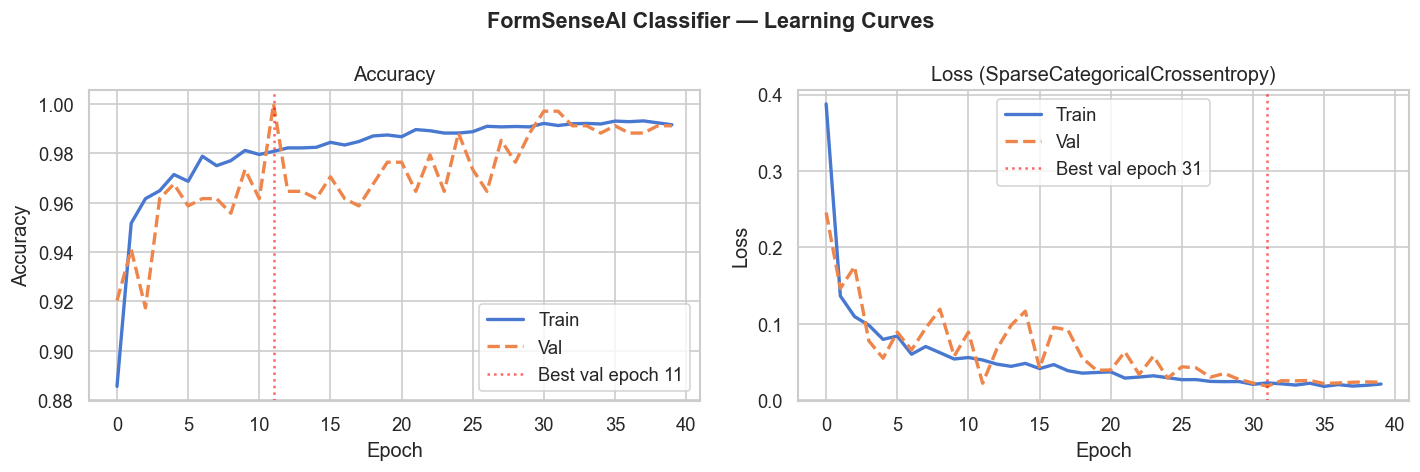

Best val accuracy : 1.0000  (epoch 11)
Final val accuracy: 0.9912
Best val loss     : 0.0184  (epoch 31)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title in zip(
    axes,
    [("accuracy", "val_accuracy"), ("loss", "val_loss")],
    ["Accuracy", "Loss (SparseCategoricalCrossentropy)"],
):
    train_col, val_col = metric
    ax.plot(history[train_col], label="Train", linewidth=2)
    ax.plot(history[val_col],   label="Val",   linewidth=2, linestyle="--")
    ax.set(title=title, xlabel="Epoch", ylabel=train_col.capitalize())
    ax.legend()
    best_fn = history[val_col].idxmin if "loss" in val_col else history[val_col].idxmax
    best_ep = best_fn()
    ax.axvline(best_ep, color="red", linestyle=":", alpha=0.6, label=f"Best val epoch {best_ep}")
    ax.legend()

plt.suptitle("FormSenseAI Classifier — Learning Curves", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()

print(f"Best val accuracy : {history['val_accuracy'].max():.4f}  (epoch {history['val_accuracy'].idxmax()})")
print(f"Final val accuracy: {history['val_accuracy'].iloc[-1]:.4f}")
print(f"Best val loss     : {history['val_loss'].min():.4f}  (epoch {history['val_loss'].idxmin()})")

### 1.3 Test split evaluation
Uses `data/keypoints/penn` if available on disk.

In [6]:
SKIP_MODEL_EVAL = not DATA_DIR.exists()
if SKIP_MODEL_EVAL:
    print(f"Data directory not found: {DATA_DIR}")
    print("   Sections 1.3 – 1.9 require the .npz keypoint files.")
    print("   The confusion matrix / F1 / calibration cells will be skipped.")
else:
    import keras
    from formcheck.classifier import ClassifierConfig, load_config
    from formcheck import skeleton
    from formcheck.train import load_videos, eval_windows

    cfg = load_config(RUN_DIR)
    model = keras.models.load_model(RUN_DIR / "model.keras", compile=False)
    print("Model loaded. Classes:", cfg.classes)

    videos = load_videos(DATA_DIR)
    splits = {s: [v for v in videos if v["split"] == s] for s in ("val", "test")}
    print({s: len(v) for s, v in splits.items()})

Model loaded. Classes: ['bench_press', 'clean_and_jerk', 'jumping_jacks', 'pullup', 'pushup', 'situp', 'squat']


{'val': 63, 'test': 547}


In [7]:
if not SKIP_MODEL_EVAL:
    x_test, y_test, owner_test = eval_windows(splits["test"], cfg)
    probs_test = model.predict(x_test, batch_size=256, verbose=0)
    pred_win   = probs_test.argmax(axis=1)
    conf_win   = probs_test.max(axis=1)
    ok_win     = pred_win == y_test

    vid_true, vid_pred, vid_conf = [], [], []
    for i in np.unique(owner_test):
        m = owner_test == i
        avg = probs_test[m].mean(axis=0)
        vid_true.append(y_test[m][0])
        vid_pred.append(int(avg.argmax()))
        vid_conf.append(float(avg.max()))
    vid_true = np.array(vid_true)
    vid_pred = np.array(vid_pred)
    vid_conf = np.array(vid_conf)

    print(f"Windows: {len(y_test)}  |  Videos: {len(vid_true)}")
    print(f"Window accuracy : {ok_win.mean():.4f}")
    print(f"Video accuracy  : {(vid_true == vid_pred).mean():.4f}")

Windows: 3303  |  Videos: 547
Window accuracy : 0.9343
Video accuracy  : 0.9890


### 1.4 Precision, Recall, and F1

In [8]:
if not SKIP_MODEL_EVAL:
    print("=" * 60)
    print("VIDEO-LEVEL  |  Test split")
    print("=" * 60)
    print(classification_report(
        vid_true, vid_pred,
        target_names=cfg.classes,
        digits=3,
    ))

    mac_f1  = f1_score(vid_true, vid_pred, average="macro")
    wt_f1   = f1_score(vid_true, vid_pred, average="weighted")
    kappa   = cohen_kappa_score(vid_true, vid_pred)
    print(f"Macro F1   : {mac_f1:.4f}")
    print(f"Weighted F1: {wt_f1:.4f}")
    print(f"Cohen κ    : {kappa:.4f}")
else:
    print("Parsing saved report (data not found — using report.txt confusion matrix)")
    classes = ["bench_press", "clean_and_jerk", "jumping_jacks", "pullup", "pushup", "situp", "squat"]
    cm = np.array([
        [71,  0,  0,  0,  0,  0,  0],
        [ 0, 43,  0,  2,  0,  0,  0],
        [ 0,  0, 56,  0,  0,  0,  0],
        [ 1,  0,  0,100,  0,  0,  0],
        [ 0,  0,  0,  0,106,  1,  0],
        [ 0,  0,  0,  0,  0, 50,  0],
        [ 0,  2,  0,  0,  0,  0,115],
    ])
    vid_true_r, vid_pred_r = [], []
    for i in range(len(classes)):
        for j in range(len(classes)):
            vid_true_r.extend([i] * cm[i, j])
            vid_pred_r.extend([j] * cm[i, j])
    vid_true_r, vid_pred_r = np.array(vid_true_r), np.array(vid_pred_r)

    print(classification_report(vid_true_r, vid_pred_r, target_names=classes, digits=3))
    print(f"Macro F1   : {f1_score(vid_true_r, vid_pred_r, average='macro'):.4f}")
    print(f"Weighted F1: {f1_score(vid_true_r, vid_pred_r, average='weighted'):.4f}")
    print(f"Cohen κ    : {cohen_kappa_score(vid_true_r, vid_pred_r):.4f}")
    vid_true, vid_pred = vid_true_r, vid_pred_r
    cfg_classes = classes

VIDEO-LEVEL  |  Test split
                precision    recall  f1-score   support

   bench_press      0.986     1.000     0.993        71
clean_and_jerk      0.956     0.956     0.956        45
 jumping_jacks      1.000     1.000     1.000        56
        pullup      0.980     0.990     0.985       101
        pushup      1.000     0.991     0.995       107
         situp      0.980     1.000     0.990        50
         squat      1.000     0.983     0.991       117

      accuracy                          0.989       547
     macro avg      0.986     0.988     0.987       547
  weighted avg      0.989     0.989     0.989       547

Macro F1   : 0.9872
Weighted F1: 0.9890
Cohen κ    : 0.9869


### 1.5 Confusion matrix heatmap

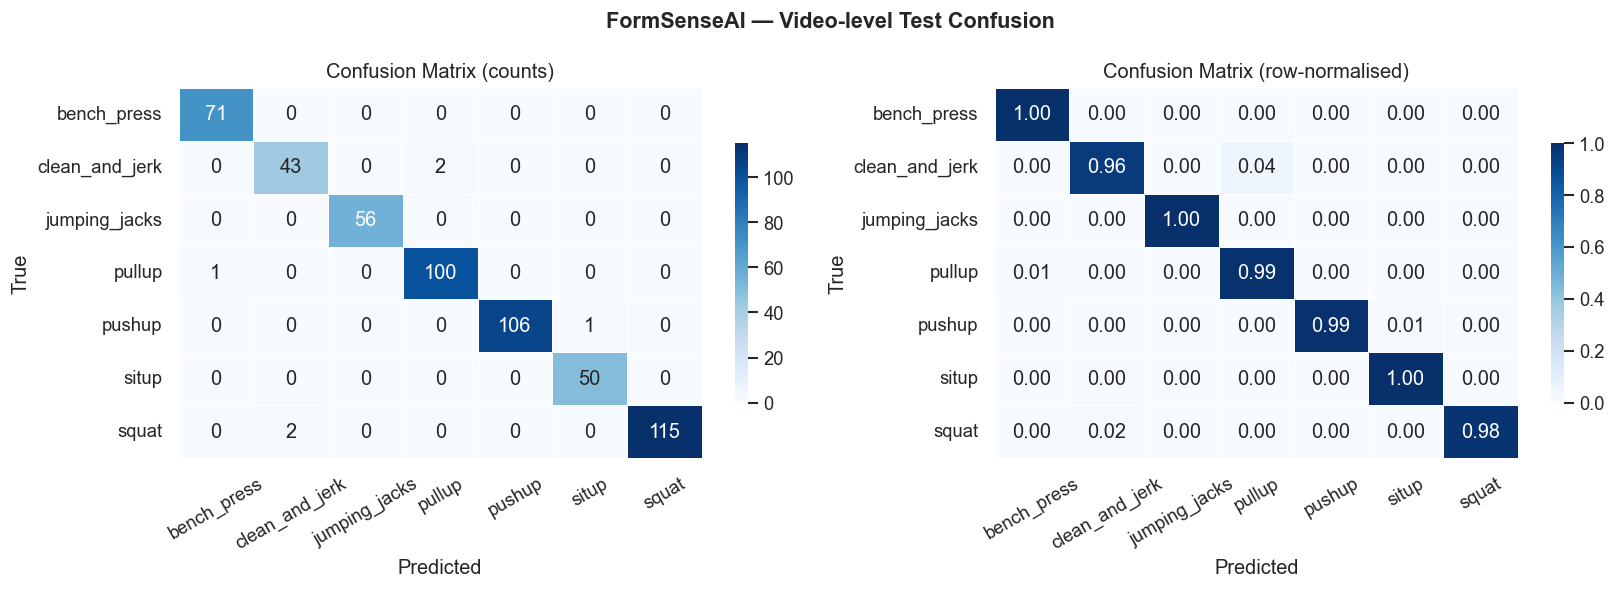

In [9]:
label_names = cfg.classes if not SKIP_MODEL_EVAL else classes

cm_raw = confusion_matrix(vid_true, vid_pred)
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes,
    [cm_raw, cm_norm],
    ["d", ".2f"],
    ["Confusion Matrix (counts)", "Confusion Matrix (row-normalised)"],
):
    sns.heatmap(
        data, annot=True, fmt=fmt,
        xticklabels=label_names, yticklabels=label_names,
        cmap="Blues", linewidths=0.4, ax=ax,
        cbar_kws={"shrink": 0.7},
    )
    ax.set(title=title, xlabel="Predicted", ylabel="True")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("FormSenseAI — Video-level Test Confusion", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

### 1.6 Per-class Precision, Recall, and F1

                Precision  Recall     F1
bench_press         0.986   1.000  0.993
clean_and_jerk      0.956   0.956  0.956
jumping_jacks       1.000   1.000  1.000
pullup              0.980   0.990  0.985
pushup              1.000   0.991  0.995
situp               0.980   1.000  0.990
squat               1.000   0.983  0.991


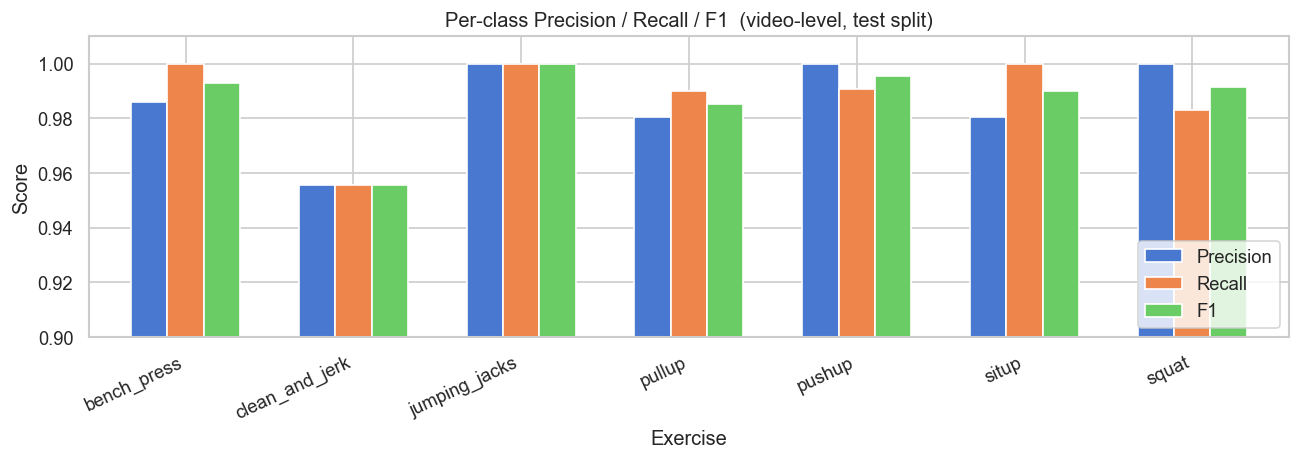

In [10]:
prec  = precision_score(vid_true, vid_pred, average=None, labels=range(len(label_names)))
rec   = recall_score(   vid_true, vid_pred, average=None, labels=range(len(label_names)))
f1    = f1_score(       vid_true, vid_pred, average=None, labels=range(len(label_names)))

metrics_df = pd.DataFrame(
    {"Precision": prec, "Recall": rec, "F1": f1},
    index=label_names,
)
print(metrics_df.round(3).to_string())

metrics_df.plot(kind="bar", figsize=(11, 4), ylim=(0.9, 1.01), edgecolor="white", width=0.65)
plt.title("Per-class Precision / Recall / F1  (video-level, test split)", fontsize=12)
plt.xlabel("Exercise")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RUN_DIR / "per_class_metrics.png", bbox_inches="tight")
plt.show()

### 1.7 Confidence distribution and AUROC

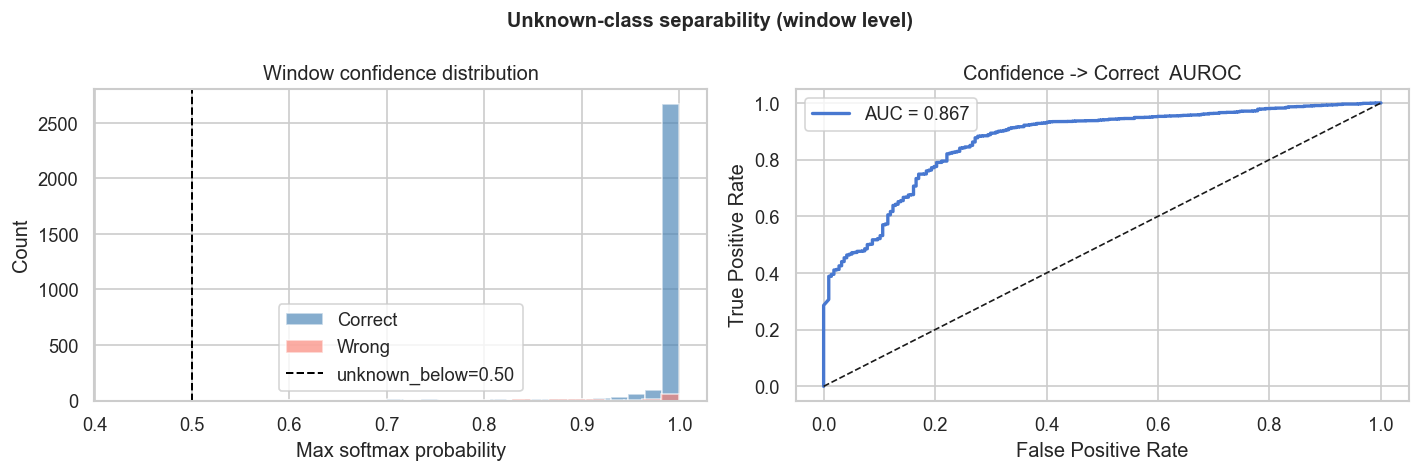

AUROC (confidence vs. correctness): 0.8668
Mean confidence — correct: 0.979  |  wrong: 0.846


In [11]:
if not SKIP_MODEL_EVAL:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    ax = axes[0]
    ax.hist(conf_win[ok_win],  bins=30, alpha=0.65, label="Correct",   color="steelblue")
    ax.hist(conf_win[~ok_win], bins=30, alpha=0.65, label="Wrong",     color="salmon")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1.2, label="unknown_below=0.50")
    ax.set(title="Window confidence distribution", xlabel="Max softmax probability", ylabel="Count")
    ax.legend()

    ax = axes[1]
    fpr, tpr, _ = roc_curve(ok_win.astype(int), conf_win)
    auc = roc_auc_score(ok_win.astype(int), conf_win)
    ax.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title="Confidence -> Correct  AUROC",
           xlabel="False Positive Rate", ylabel="True Positive Rate")
    ax.legend()

    plt.suptitle("Unknown-class separability (window level)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(RUN_DIR / "confidence_auroc.png", bbox_inches="tight")
    plt.show()
    print(f"AUROC (confidence vs. correctness): {auc:.4f}")
    print(f"Mean confidence — correct: {conf_win[ok_win].mean():.3f}  |  wrong: {conf_win[~ok_win].mean():.3f}")
else:
    print("Skipped: requires model + data for per-window probabilities.")

### 1.8 Calibration (ECE and Brier score)
Checks how closely softmax confidence matches empirical accuracy.

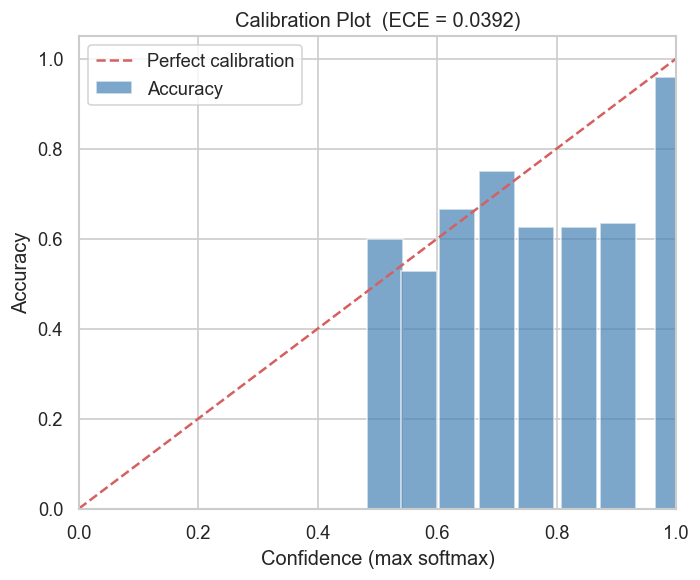

Expected Calibration Error (ECE): 0.0392
Multiclass Brier Score           : 0.0154


In [12]:
if not SKIP_MODEL_EVAL:
    n_bins = 15
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_acc, bin_conf_mean, bin_count = [], [], []

    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (conf_win >= lo) & (conf_win < hi)
        if mask.sum() == 0:
            bin_acc.append(np.nan)
            bin_conf_mean.append((lo + hi) / 2)
            bin_count.append(0)
        else:
            bin_acc.append(ok_win[mask].mean())
            bin_conf_mean.append(conf_win[mask].mean())
            bin_count.append(mask.sum())

    bin_acc    = np.array(bin_acc)
    bin_conf_m = np.array(bin_conf_mean)
    bin_count  = np.array(bin_count)
    total      = len(conf_win)

    ece = np.nansum(bin_count / total * np.abs(bin_acc - bin_conf_m))

    fig, ax = plt.subplots(figsize=(6, 5))
    valid = ~np.isnan(bin_acc)
    ax.bar(bin_conf_m[valid], bin_acc[valid],
           width=(bin_edges[1] - bin_edges[0]) * 0.9,
           alpha=0.7, label="Accuracy", color="steelblue", edgecolor="white")
    ax.plot([0, 1], [0, 1], "r--", lw=1.5, label="Perfect calibration")
    ax.set(title=f"Calibration Plot  (ECE = {ece:.4f})",
           xlabel="Confidence (max softmax)", ylabel="Accuracy",
           xlim=(0, 1), ylim=(0, 1.05))
    ax.legend()
    plt.tight_layout()
    plt.savefig(RUN_DIR / "calibration.png", bbox_inches="tight")
    plt.show()
    print(f"Expected Calibration Error (ECE): {ece:.4f}")
    n_cls  = probs_test.shape[1]
    y_oh   = np.eye(n_cls)[y_test]
    brier  = float(np.mean((probs_test - y_oh) ** 2))
    print(f"Multiclass Brier Score           : {brier:.4f}")
else:
    print("Skipped: requires model + data.")

### 1.9 Top-k accuracy and inference latency

In [13]:
import time, keras
from formcheck.classifier import load_config

cfg_lat = cfg if not SKIP_MODEL_EVAL else load_config(RUN_DIR)
model_lat = model if not SKIP_MODEL_EVAL else keras.models.load_model(RUN_DIR / "model.keras", compile=False)

if not SKIP_MODEL_EVAL:
    top2 = (probs_test.argsort(axis=1)[:, -2:] == y_test[:, None]).any(axis=1).mean()
    print(f"Window Top-1 accuracy: {ok_win.mean():.4f}")
    print(f"Window Top-2 accuracy: {top2:.4f}\n")
else:
    print("Top-1 / Top-2 skipped (requires data/keypoints/penn/*.npz).\n")

sample = np.zeros((1, cfg_lat.window, cfg_lat.num_features), dtype=np.float32)
_ = model_lat(sample, training=False)
N_RUNS = 200
t0 = time.perf_counter()
for _ in range(N_RUNS):
    _ = model_lat(sample, training=False)
ms = (time.perf_counter() - t0) / N_RUNS * 1000
print(f"Single-window inference latency : {ms:.2f} ms  ({1000/ms:.0f} windows/s)")
print(f"At {cfg_lat.fps:.0f} fps the frame budget is  : {1000/cfg_lat.fps:.1f} ms/frame")
print(f"Headroom factor                 : {(1000/cfg_lat.fps)/ms:.1f}x")

Window Top-1 accuracy: 0.9343
Window Top-2 accuracy: 0.9927



Single-window inference latency : 17.24 ms  (58 windows/s)
At 30 fps the frame budget is  : 33.3 ms/frame
Headroom factor                 : 1.9x


## 2: Rule Engine Metrics
### 2.1 Rep-count MAE on synthetic signals

In [14]:
import numpy as np
from formcheck.rules import RepTracker, load_rules
from formcheck.skeleton import ANGLE_NAMES

rules = load_rules()
FPS   = 30.0
FRONT, SIDE = 0.8, 0.2


def cosine_reps(top, bottom, n_reps=5, seconds=2.0):
    """n_reps cosine cycles (top -> bottom -> top) with rest padding."""
    per   = int(seconds * FPS)
    phase = np.linspace(0, 2 * np.pi, per, endpoint=False)
    rep   = bottom + (top - bottom) * (0.5 + 0.5 * np.cos(phase))
    return np.concatenate([np.full(int(FPS / 2), top),
                            *([rep] * n_reps),
                            np.full(int(FPS), top)])


def run_tracker(exercise, signals, view, true_reps):
    tracker = RepTracker(exercise, rules)
    n       = len(next(iter(signals.values())))
    for i in range(n):
        frame = {name: float("nan") for name in (*ANGLE_NAMES, "torso_lean")}
        frame.update({k: float(v[i]) for k, v in signals.items()})
        tracker.update(frame, view, i / FPS)
    tracker.flush()
    return tracker.reps, abs(tracker.reps - true_reps)


SCENARIOS = [
    ("squat",        "knee",     175,  85,  SIDE),
    ("pushup",       "elbow",    170,  80,  SIDE),
    ("situp",        "hip",      130,  70,  SIDE),
    ("pullup",       "elbow",    160,  60,  FRONT),
    ("bench_press",  "elbow",    170,  80,  FRONT),
    ("jumping_jacks","shoulder",  20, 160,  FRONT),
]

TRUE_REPS = 5
results = []
for n_reps in (3, 5, 8):
    for exercise, angle_key, top, bottom, view in SCENARIOS:
        signal = cosine_reps(top, bottom, n_reps)
        sigs   = {f"left_{angle_key}": signal, f"right_{angle_key}": signal}
        if exercise == "squat":
            sigs["torso_lean"] = signal * 0 + 20
        pred, err = run_tracker(exercise, sigs, view, n_reps)
        results.append({"exercise": exercise, "true_reps": n_reps,
                        "pred_reps": pred, "abs_error": err})

rep_df = pd.DataFrame(results)
rep_df

,exercise,true_reps,pred_reps,abs_error
0,squat,3,3,0
1,pushup,3,3,0
2,situp,3,3,0
3,pullup,3,3,0
4,bench_press,3,3,0
5,jumping_jacks,3,3,0
6,squat,5,5,0
7,pushup,5,5,0
8,situp,5,5,0
9,pullup,5,5,0


In [15]:
summary = rep_df.groupby("exercise").agg(
    MAE=("abs_error", "mean"),
    Max_error=("abs_error", "max"),
    Perfect_pct=("abs_error", lambda x: (x == 0).mean() * 100),
).round(3)
print("=" * 50)
print("Rep-count MAE / per-exercise summary")
print("=" * 50)
print(summary.to_string())

overall_mae = rep_df["abs_error"].mean()
overall_perfect = (rep_df["abs_error"] == 0).mean() * 100
print(f"\nOverall MAE      : {overall_mae:.3f} reps")
print(f"Perfect accuracy : {overall_perfect:.1f}%")

Rep-count MAE / per-exercise summary
               MAE  Max_error  Perfect_pct
exercise                                  
bench_press    0.0          0        100.0
jumping_jacks  0.0          0        100.0
pullup         0.0          0        100.0
pushup         0.0          0        100.0
situp          0.0          0        100.0
squat          0.0          0        100.0

Overall MAE      : 0.000 reps
Perfect accuracy : 100.0%


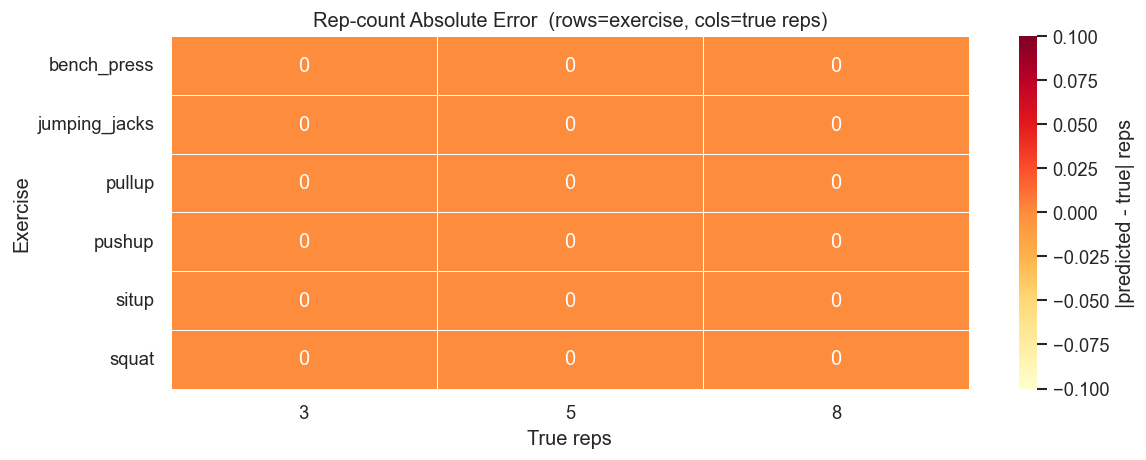

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
pivot = rep_df.pivot_table(index="exercise", columns="true_reps", values="abs_error")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.4,
            cbar_kws={"label": "|predicted - true| reps"}, ax=ax)
ax.set(title="Rep-count Absolute Error  (rows=exercise, cols=true reps)",
       xlabel="True reps", ylabel="Exercise")
plt.tight_layout()
plt.show()

### 2.2 Cue precision and recall (synthetic scenarios)

In [17]:
from formcheck.rules import RepTracker


def collect_cues(exercise, signals, view):
    tracker = RepTracker(exercise, rules)
    n = len(next(iter(signals.values())))
    cue_texts = []
    for i in range(n):
        frame = {name: float("nan") for name in (*ANGLE_NAMES, "torso_lean")}
        frame.update({k: float(v[i]) for k, v in signals.items()})
        cue_texts += [c.text for c in tracker.update(frame, view, i / FPS)]
    cue_texts += [c.text for c in tracker.flush()]
    return set(cue_texts)


CUE_SCENARIOS = [
    ("Squat too shallow",
     "squat",
     lambda: {"left_knee": cosine_reps(175, 125),
              "right_knee": cosine_reps(175, 125),
              "torso_lean": cosine_reps(175, 125) * 0 + 20},
     SIDE, "Go deeper", True),

    ("Squat good depth",
     "squat",
     lambda: {"left_knee": cosine_reps(175, 85),
              "right_knee": cosine_reps(175, 85),
              "torso_lean": cosine_reps(175, 85) * 0 + 20},
     SIDE, "Go deeper", False),

    ("Push-up hip sag",
     "pushup",
     lambda: (lambda e: {"left_elbow": e, "right_elbow": e,
                          "left_body":  np.where(e < 120, 140.0, 175.0),
                          "right_body": np.where(e < 120, 140.0, 175.0)})(cosine_reps(170, 80)),
     SIDE, "Keep your body in a straight line from shoulders to ankles", True),

    ("Push-up good form",
     "pushup",
     lambda: (lambda e: {"left_elbow": e, "right_elbow": e,
                          "left_body":  e * 0 + 175.0,
                          "right_body": e * 0 + 175.0})(cosine_reps(170, 80)),
     SIDE, "Keep your body in a straight line from shoulders to ankles", False),

    ("Jumping jacks asymmetry",
     "jumping_jacks",
     lambda: {"left_shoulder":  cosine_reps(20, 120, seconds=1.0),
              "right_shoulder": cosine_reps(20, 170, seconds=1.0)},
     FRONT, "Lift your left arm further", True),

    ("Jumping jacks symmetric",
     "jumping_jacks",
     lambda: {"left_shoulder":  cosine_reps(20, 160, seconds=1.0),
              "right_shoulder": cosine_reps(20, 160, seconds=1.0)},
     FRONT, "Lift your left arm further", False),

    ("Pull-up not fully locked",
     "pullup",
     lambda: (lambda e: {"left_elbow": e, "right_elbow": e})(cosine_reps(130, 60)),
     FRONT, "Lower all the way to straight arms", True),

    ("Squat chest lean",
     "squat",
     lambda: (lambda k: {"left_knee":   k,
                          "right_knee":  k,
                          "torso_lean":  np.where(k < 120, 65.0, 20.0)})(cosine_reps(175, 85)),
     SIDE, "Keep your chest up", True),

    ("Clean-and-jerk no lockout",
     "clean_and_jerk",
     lambda: (lambda s: {"left_shoulder":  s,
                          "right_shoulder": s,
                          "left_elbow":     np.where(s > 130, 140.0, 90.0),
                          "right_elbow":    np.where(s > 130, 140.0, 90.0)})
             (np.concatenate([np.full(15, 20.0), np.linspace(20, 165, 30), np.full(60, 165.0)])),
     FRONT, "Lock out your arms overhead", True),
]

cue_results = []
for label, exercise, build_sigs, view, expected_cue, should_fire in CUE_SCENARIOS:
    sigs   = build_sigs()
    fired  = collect_cues(exercise, sigs, view)
    hit    = expected_cue in fired
    if should_fire:
        result = "TP" if hit else "FN"
    else:
        result = "FP" if hit else "TN"
    cue_results.append({
        "Scenario": label,
        "Expected cue fires": should_fire,
        "Cue fired": hit,
        "Result": result,
        "Other cues fired": str(sorted(fired - {expected_cue})) if fired - {expected_cue} else "-",
    })

cue_df = pd.DataFrame(cue_results)
cue_df

,Scenario,Expected cue fires,Cue fired,Result,Other cues fired
0,Squat too shallow,True,True,TP,-
1,Squat good depth,False,False,TN,-
2,Push-up hip sag,True,True,TP,-
3,Push-up good form,False,False,TN,-
4,Jumping jacks asymmetry,True,True,TP,-
5,Jumping jacks symmetric,False,False,TN,-
6,Pull-up not fully locked,True,False,FN,-
7,Squat chest lean,True,True,TP,-
8,Clean-and-jerk no lockout,True,True,TP,-


In [18]:
counts = cue_df["Result"].value_counts()
tp = counts.get("TP", 0)
tn = counts.get("TN", 0)
fp = counts.get("FP", 0)
fn = counts.get("FN", 0)

precision_cue = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
recall_cue    = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
f1_cue        = 2 * precision_cue * recall_cue / (precision_cue + recall_cue) \
                if (precision_cue + recall_cue) > 0 else float("nan")
accuracy_cue  = (tp + tn) / len(cue_df)

print("=" * 40)
print("Cue-firing evaluation (synthetic)")
print("=" * 40)
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")
print(f"Precision : {precision_cue:.3f}")
print(f"Recall    : {recall_cue:.3f}")
print(f"F1        : {f1_cue:.3f}")
print(f"Accuracy  : {accuracy_cue:.3f}")

Cue-firing evaluation (synthetic)
TP=5  TN=3  FP=0  FN=1
Precision : 1.000
Recall    : 0.833
F1        : 0.909
Accuracy  : 0.889


### 2.3 Good-form false-positive check

In [19]:
GOOD_FORM = [
    ("squat",         {"left_knee": cosine_reps(175, 85),
                        "right_knee": cosine_reps(175, 85),
                        "torso_lean": cosine_reps(175, 85) * 0 + 20},  SIDE),
    ("pushup",        (lambda e: {"left_elbow": e, "right_elbow": e,
                                   "left_body":  e * 0 + 175.0,
                                   "right_body": e * 0 + 175.0})(cosine_reps(170, 80)),  SIDE),
    ("situp",         {"left_hip":  cosine_reps(130, 70),
                        "right_hip": cosine_reps(130, 70)},  SIDE),
    ("pullup",        {"left_elbow":  cosine_reps(160, 50),
                        "right_elbow": cosine_reps(160, 50)},  FRONT),
    ("bench_press",   {"left_elbow":  cosine_reps(170, 80),
                        "right_elbow": cosine_reps(170, 80)},  FRONT),
    ("jumping_jacks", {"left_shoulder":  cosine_reps(20, 160, seconds=1.0),
                        "right_shoulder": cosine_reps(20, 160, seconds=1.0)},  FRONT),
]

print(f"{'Exercise':<20} {'Cues fired (should be none)'}")
print("-" * 55)
all_pass = True
for exercise, sigs, view in GOOD_FORM:
    fired = collect_cues(exercise, sigs, view)
    status = "PASS" if not fired else f"FAIL: SPURIOUS: {fired}"
    if fired:
        all_pass = False
    print(f"{exercise:<20} {status}")

print()
print("All good-form tests passed!" if all_pass else "Some spurious cues detected — review thresholds.")

Exercise             Cues fired (should be none)
-------------------------------------------------------
squat                PASS
pushup               PASS
situp                PASS
pullup               PASS
bench_press          PASS
jumping_jacks        PASS

All good-form tests passed!


### 2.4 View classifier accuracy

In [20]:
from formcheck.rules import classify_view, load_rules

view_cfg = rules["view"]

VIEW_CASES = [
    (0.70, "front"), (0.60, "front"), (0.56, "front"),
    (0.45, "diagonal"), (0.40, "diagonal"), (0.36, "diagonal"),
    (0.30, "side"),  (0.20, "side"),  (0.10, "side"),
    (float("nan"), "unknown"),
]

view_results = []
for ratio, expected in VIEW_CASES:
    pred = classify_view(ratio, view_cfg)
    view_results.append({"ratio": ratio, "expected": expected,
                          "predicted": pred, "correct": pred == expected})

vdf = pd.DataFrame(view_results)
print(vdf.to_string(index=False))
print(f"\nView classifier accuracy: {vdf['correct'].mean():.2%}")

 ratio expected predicted  correct
  0.70    front     front     True
  0.60    front     front     True
  0.56    front     front     True
  0.45 diagonal  diagonal     True
  0.40 diagonal  diagonal     True
  0.36 diagonal  diagonal     True
  0.30     side      side     True
  0.20     side      side     True
  0.10     side      side     True
   NaN  unknown   unknown     True

View classifier accuracy: 100.00%


## 3: Pose Estimator Metrics
### 3.1 Heatmap decode precision (sub-pixel error)

In [21]:
from harness.pose import HEATMAP_SIGMA, NUM_KEYPOINTS, decode_heatmaps

INPUT_SIZE    = 192
HEATMAP_STRIDE = 4
HM            = INPUT_SIZE // HEATMAP_STRIDE


def render_heatmaps(kps):
    """(N, K, 2) -> (N, HM, HM, K) Gaussian heatmaps."""
    centers = np.arange(HM, dtype=np.float32) + 0.5
    mx = kps[..., 0] / HEATMAP_STRIDE
    my = kps[..., 1] / HEATMAP_STRIDE
    gx = np.exp(-((centers[None, :, None] - mx[:, None, :]) ** 2) / (2 * HEATMAP_SIGMA ** 2))
    gy = np.exp(-((centers[None, :, None] - my[:, None, :]) ** 2) / (2 * HEATMAP_SIGMA ** 2))
    return (gy[:, :, None, :] * gx[:, None, :, :]).astype(np.float32)


rng  = np.random.default_rng(42)
N    = 50
kps_gt = rng.uniform(12.0, INPUT_SIZE - 12.0, size=(N, NUM_KEYPOINTS, 2)).astype(np.float32)
heats  = render_heatmaps(kps_gt)
coords, scores = decode_heatmaps(heats, HEATMAP_STRIDE, HEATMAP_SIGMA)

errors = np.abs(coords - kps_gt)
err_px = np.linalg.norm(errors, axis=-1)

print(f"Decode error (Euclidean px) — N={N} frames, {NUM_KEYPOINTS} joints")
print(f"  Mean  : {err_px.mean():.4f} px")
print(f"  Median: {np.median(err_px):.4f} px")
print(f"  Max   : {err_px.max():.4f} px")
print(f"  All within 0.5 px: {(err_px < 0.5).all()}")

Decode error (Euclidean px) — N=50 frames, 17 joints
  Mean  : 0.0237 px
  Median: 0.0000 px
  Max   : 0.4167 px
  All within 0.5 px: True


### 3.2 Percentage of Correct Keypoints (PCK)

PCK @ each threshold:
              PCK_overall
threshold_px             
1                     1.0
2                     1.0
3                     1.0
5                     1.0
10                    1.0


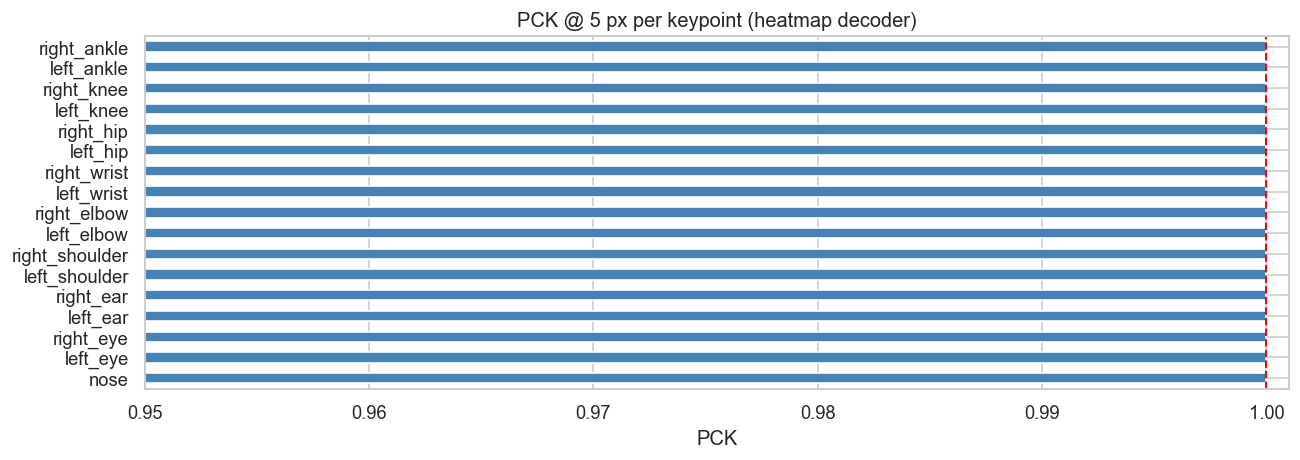

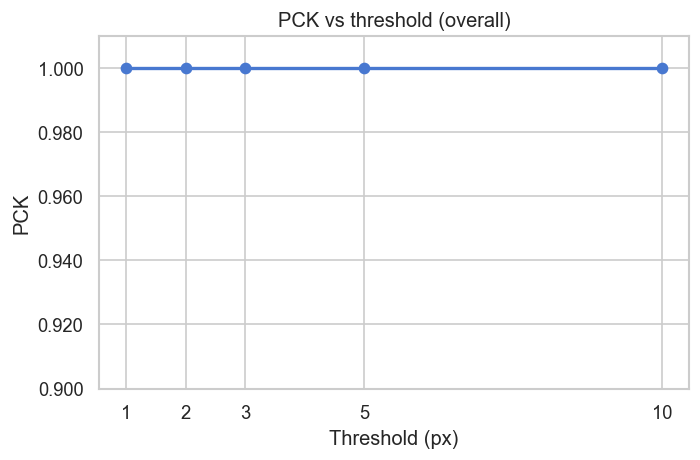

In [22]:
from harness.pose import KEYPOINT_NAMES

THRESHOLDS = [1, 2, 3, 5, 10]

pck_rows = []
for thresh in THRESHOLDS:
    pck_overall = (err_px < thresh).mean()
    per_joint   = (err_px < thresh).mean(axis=0)
    row = {"threshold_px": thresh, "PCK_overall": pck_overall}
    for name, v in zip(KEYPOINT_NAMES, per_joint):
        row[name] = v
    pck_rows.append(row)

pck_df = pd.DataFrame(pck_rows).set_index("threshold_px")
print("PCK @ each threshold:")
print(pck_df[["PCK_overall"]].round(4).to_string())

per_joint_5 = pck_df.loc[5, list(KEYPOINT_NAMES)]
fig, ax = plt.subplots(figsize=(11, 4))
per_joint_5.sort_values().plot(kind="barh", ax=ax, color="steelblue", edgecolor="white")
ax.axvline(1.0, color="red", linestyle="--", lw=1.2)
ax.set(title="PCK @ 5 px per keypoint (heatmap decoder)",
       xlabel="PCK", xlim=(0.95, 1.001))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(THRESHOLDS, pck_df["PCK_overall"].values, "o-", lw=2, markersize=6)
ax.set(title="PCK vs threshold (overall)", xlabel="Threshold (px)",
       ylabel="PCK", ylim=(0.9, 1.01), xticks=THRESHOLDS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.3f}"))
plt.tight_layout()
plt.show()

### 3.3 Joint detection rate

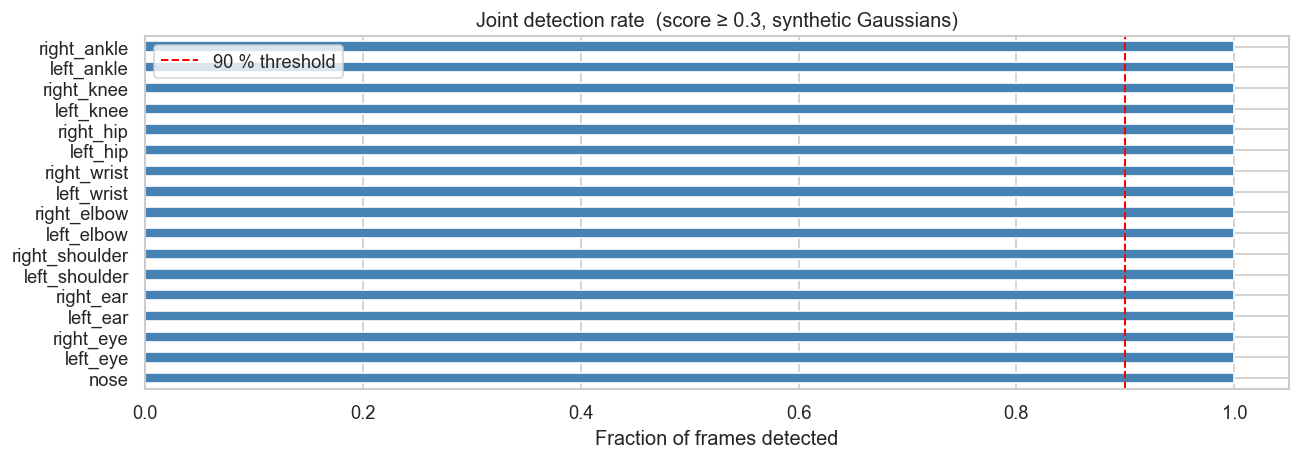

Mean joint detection rate: 1.0000
Joints below 90% detection: None


In [23]:
THRESHOLD = 0.3

vis_rate = (scores >= THRESHOLD).mean(axis=0)
vis_df = pd.Series(vis_rate, index=KEYPOINT_NAMES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 4))
vis_df.plot(kind="barh", ax=ax,
            color=["salmon" if v < 0.9 else "steelblue" for v in vis_df],
            edgecolor="white")
ax.axvline(0.9, color="red", linestyle="--", lw=1.2, label="90 % threshold")
ax.set(title=f"Joint detection rate  (score ≥ {THRESHOLD}, synthetic Gaussians)",
       xlabel="Fraction of frames detected", xlim=(0.0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean joint detection rate: {vis_rate.mean():.4f}")
low_vis = [n for n, v in zip(KEYPOINT_NAMES, vis_rate) if v < 0.9]
print(f"Joints below 90% detection: {low_vis if low_vis else 'None'}")

### 3.4 Flip consistency

In [24]:
from harness.pose import FLIP_INDEX, flip_heatmaps

heat_rand = rng.random((5, HM, HM, NUM_KEYPOINTS)).astype(np.float32)
diff = np.abs(flip_heatmaps(flip_heatmaps(heat_rand, FLIP_INDEX), FLIP_INDEX) - heat_rand).max()
print(f"Max |flip(flip(x)) - x|: {diff}  -> involution holds: {diff == 0.0}")

Max |flip(flip(x)) - x|: 0.0  -> involution holds: True


## 4: Summary Dashboard

In [25]:
if SKIP_MODEL_EVAL:
    mac_f1 = f1_score(vid_true, vid_pred, average="macro")
    wt_f1 = f1_score(vid_true, vid_pred, average="weighted")
    kappa = cohen_kappa_score(vid_true, vid_pred)

summary_table = pd.DataFrame([
    ("Classifier", "Video accuracy", f"{(vid_true == vid_pred).mean():.4f}"),
    ("Classifier", "Macro F1", f"{mac_f1:.4f}"),
    ("Classifier", "Weighted F1", f"{wt_f1:.4f}"),
    ("Classifier", "Cohen kappa", f"{kappa:.4f}"),
    ("Rule engine", "Rep-count MAE", f"{overall_mae:.3f} reps"),
    ("Rule engine", "Cue F1", f"{f1_cue:.3f}"),
    ("Pose estimator", "Mean decode error", f"{err_px.mean():.4f} px"),
    ("Pose estimator", "PCK @ 5 px", f"{pck_df.loc[5, 'PCK_overall']:.4f}"),
], columns=["Component", "Metric", "Value"])

summary_table

,Component,Metric,Value
0,Classifier,Video accuracy,0.9890
1,Classifier,Macro F1,0.9872
2,Classifier,Weighted F1,0.9890
3,Classifier,Cohen kappa,0.9869
4,Rule engine,Rep-count MAE,0.000 reps
5,Rule engine,Cue F1,0.909
6,Pose estimator,Mean decode error,0.0237 px
7,Pose estimator,PCK @ 5 px,1.0000
